# Figure 5c: image-matching accuracy at 100 ms and 200 ms

Per-participant accuracy in the image-matching experiment at both presentation times, tested against chance (0.5)
with one-sided one-sample t-tests. Reads the anonymized response files under
`$BONNER_CACHING_HOME/behavior/image_matching_experiment/`, which `python scripts/download_behavior_data.py`
downloads (see README).

In [1]:
import os

from dotenv import load_dotenv

load_dotenv()  # before any lib/bonner import: bonner reads BONNER_CACHING_HOME when first imported
BONNER_CACHING_HOME = os.environ["BONNER_CACHING_HOME"]

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

import seaborn as sns
import matplotlib.pyplot as plt

# Font and line sizes match the published panel c: PANEL_SCALE scales seaborn's "paper" context so that the
# ratio of axis height to tick-glyph height equals the published panel's, and TARGET_AXIS_MM sets the axis height.
TARGET_AXIS_PER_GLYPH = 1045 / 38.5   # axis height / tick-glyph height (px) of the published panel c
NATIVE_AXIS_PER_GLYPH = 1645 / 35.5   # the same ratio for an unscaled "paper" render
PANEL_SCALE = NATIVE_AXIS_PER_GLYPH / TARGET_AXIS_PER_GLYPH
TARGET_AXIS_MM = 1645 / 600 * 25.4    # axis height of the unscaled render at 600 dpi

_paper = sns.plotting_context("paper")
sns.set_theme(
    context="paper",
    style="ticks",
    palette="Set2",
    rc={
        # every entry of the context dict is a font size or a line/tick width, so scaling them all
        # together reproduces the published panel's appearance
        **{k: v * PANEL_SCALE for k, v in _paper.items()},
        "figure.dpi": 600, "savefig.dpi": 600,
        "savefig.bbox": "tight",
    },
)
print(f"panel scale {PANEL_SCALE:.4f}, target axis height {TARGET_AXIS_MM:.2f} mm")

panel scale 1.7072, target axis height 69.64 mm


In [3]:
BEHAVIOR_ROOT = Path(BONNER_CACHING_HOME) / "behavior" / "image_matching_experiment"

# the two runs of the image-matching experiment, as scripts/download_behavior_data.py lays them out
RUNS = {
    "100 ms": BEHAVIOR_ROOT / "v01_time=01_pct=65" / "data" / "responses",
    "200 ms": BEHAVIOR_ROOT / "v00_time=02" / "data" / "responses",
}
TIME_ORDER = ["100 ms", "200 ms"]

for label, path in RUNS.items():
    n_files = len(list(path.glob("*.json")))
    print(f"{label}: {n_files} participants  <- $BONNER_CACHING_HOME/{path.relative_to(BONNER_CACHING_HOME)}")

100 ms: 50 participants  <- $BONNER_CACHING_HOME/behavior/image_matching_experiment/v01_time=01_pct=65/data/responses
200 ms: 50 participants  <- $BONNER_CACHING_HOME/behavior/image_matching_experiment/v00_time=02/data/responses


In [4]:
def load_responses(results_dir):
    # flatten one run's per-participant JSON files into a tidy trial-level frame
    rows = []
    for json_file in sorted(results_dir.glob("*.json")):
        with open(json_file, "r") as f:
            result = json.load(f)
        participant_info = {"participant_number": result.get("participant_number")}
        for response in result.get("responses", []):
            rows.append({**participant_info, **response})
    return pd.DataFrame(rows)


df_all = pd.concat(
    [load_responses(path).assign(time_point=label) for label, path in RUNS.items()],
    ignore_index=True,
)
df_all["time_point"] = pd.Categorical(df_all["time_point"], categories=TIME_ORDER, ordered=True)
df_all.shape

(10615, 16)

In [5]:
# quality-control checks: accuracy on the practice and catch trials
for label in TIME_ORDER:
    sub = df_all[df_all["time_point"] == label]
    practice = sub[sub["trial_id"] == "example_trial"]
    catch = sub[sub["is_catch_trial"] == True]
    print(f"--- {label} ---")
    print(f"  practice accuracy: {practice.groupby('participant_number')['is_correct'].mean().mean():.2%}")
    print(f"  catch accuracy:    {catch.groupby('participant_number')['is_correct'].mean().mean():.2%}")

--- 100 ms ---
  practice accuracy: 99.00%
  catch accuracy:    98.40%
--- 200 ms ---
  practice accuracy: 100.00%
  catch accuracy:    95.60%


In [6]:
# experiment trials only: drop practice and catch trials, then average within participant
df = df_all[(df_all["trial_id"] != "example_trial") & (df_all["is_catch_trial"] != True)]
accuracy = (
    df.groupby(["time_point", "participant_number"], observed=True)["is_correct"]
    .mean()
    .rename("accuracy")
    .reset_index()
)

stats_rows = []
for label in TIME_ORDER:
    values = accuracy.loc[accuracy["time_point"] == label, "accuracy"].to_numpy()
    t_stat, p_value = stats.ttest_1samp(values, 0.5, alternative="greater")
    std = np.std(values, ddof=1)
    stats_rows.append(
        {
            "time_point": label,
            "n": len(values),
            "mean": values.mean(),
            "sd": std,
            "t": t_stat,
            "p": p_value,
            "cohens_d": (values.mean() - 0.5) / std,
        }
    )

summary = pd.DataFrame(stats_rows).set_index("time_point")
summary

,n,mean,sd,t,p,cohens_d
time_point,,,,,,
100 ms,50,0.5654,0.049537,9.335395,9.380092e-13,1.320224
200 ms,50,0.6222,0.059050,14.633108,8.168297e-20,2.069434


In [7]:
# the statistics the manuscript reports for both time points
for label, row in summary.iterrows():
    print(
        f"{label}: M={row['mean']:.2f}, SD={row['sd']:.2f}, "
        f"t({int(row['n']) - 1})={row['t']:.2f}, p={row['p']:.3g}, d={row['cohens_d']:.2f}"
    )

100 ms: M=0.57, SD=0.05, t(49)=9.34, p=9.38e-13, d=1.32
200 ms: M=0.62, SD=0.06, t(49)=14.63, p=8.17e-20, d=2.07


axes box 62.06 x 69.64 mm (target 62.06 x 69.64 mm)


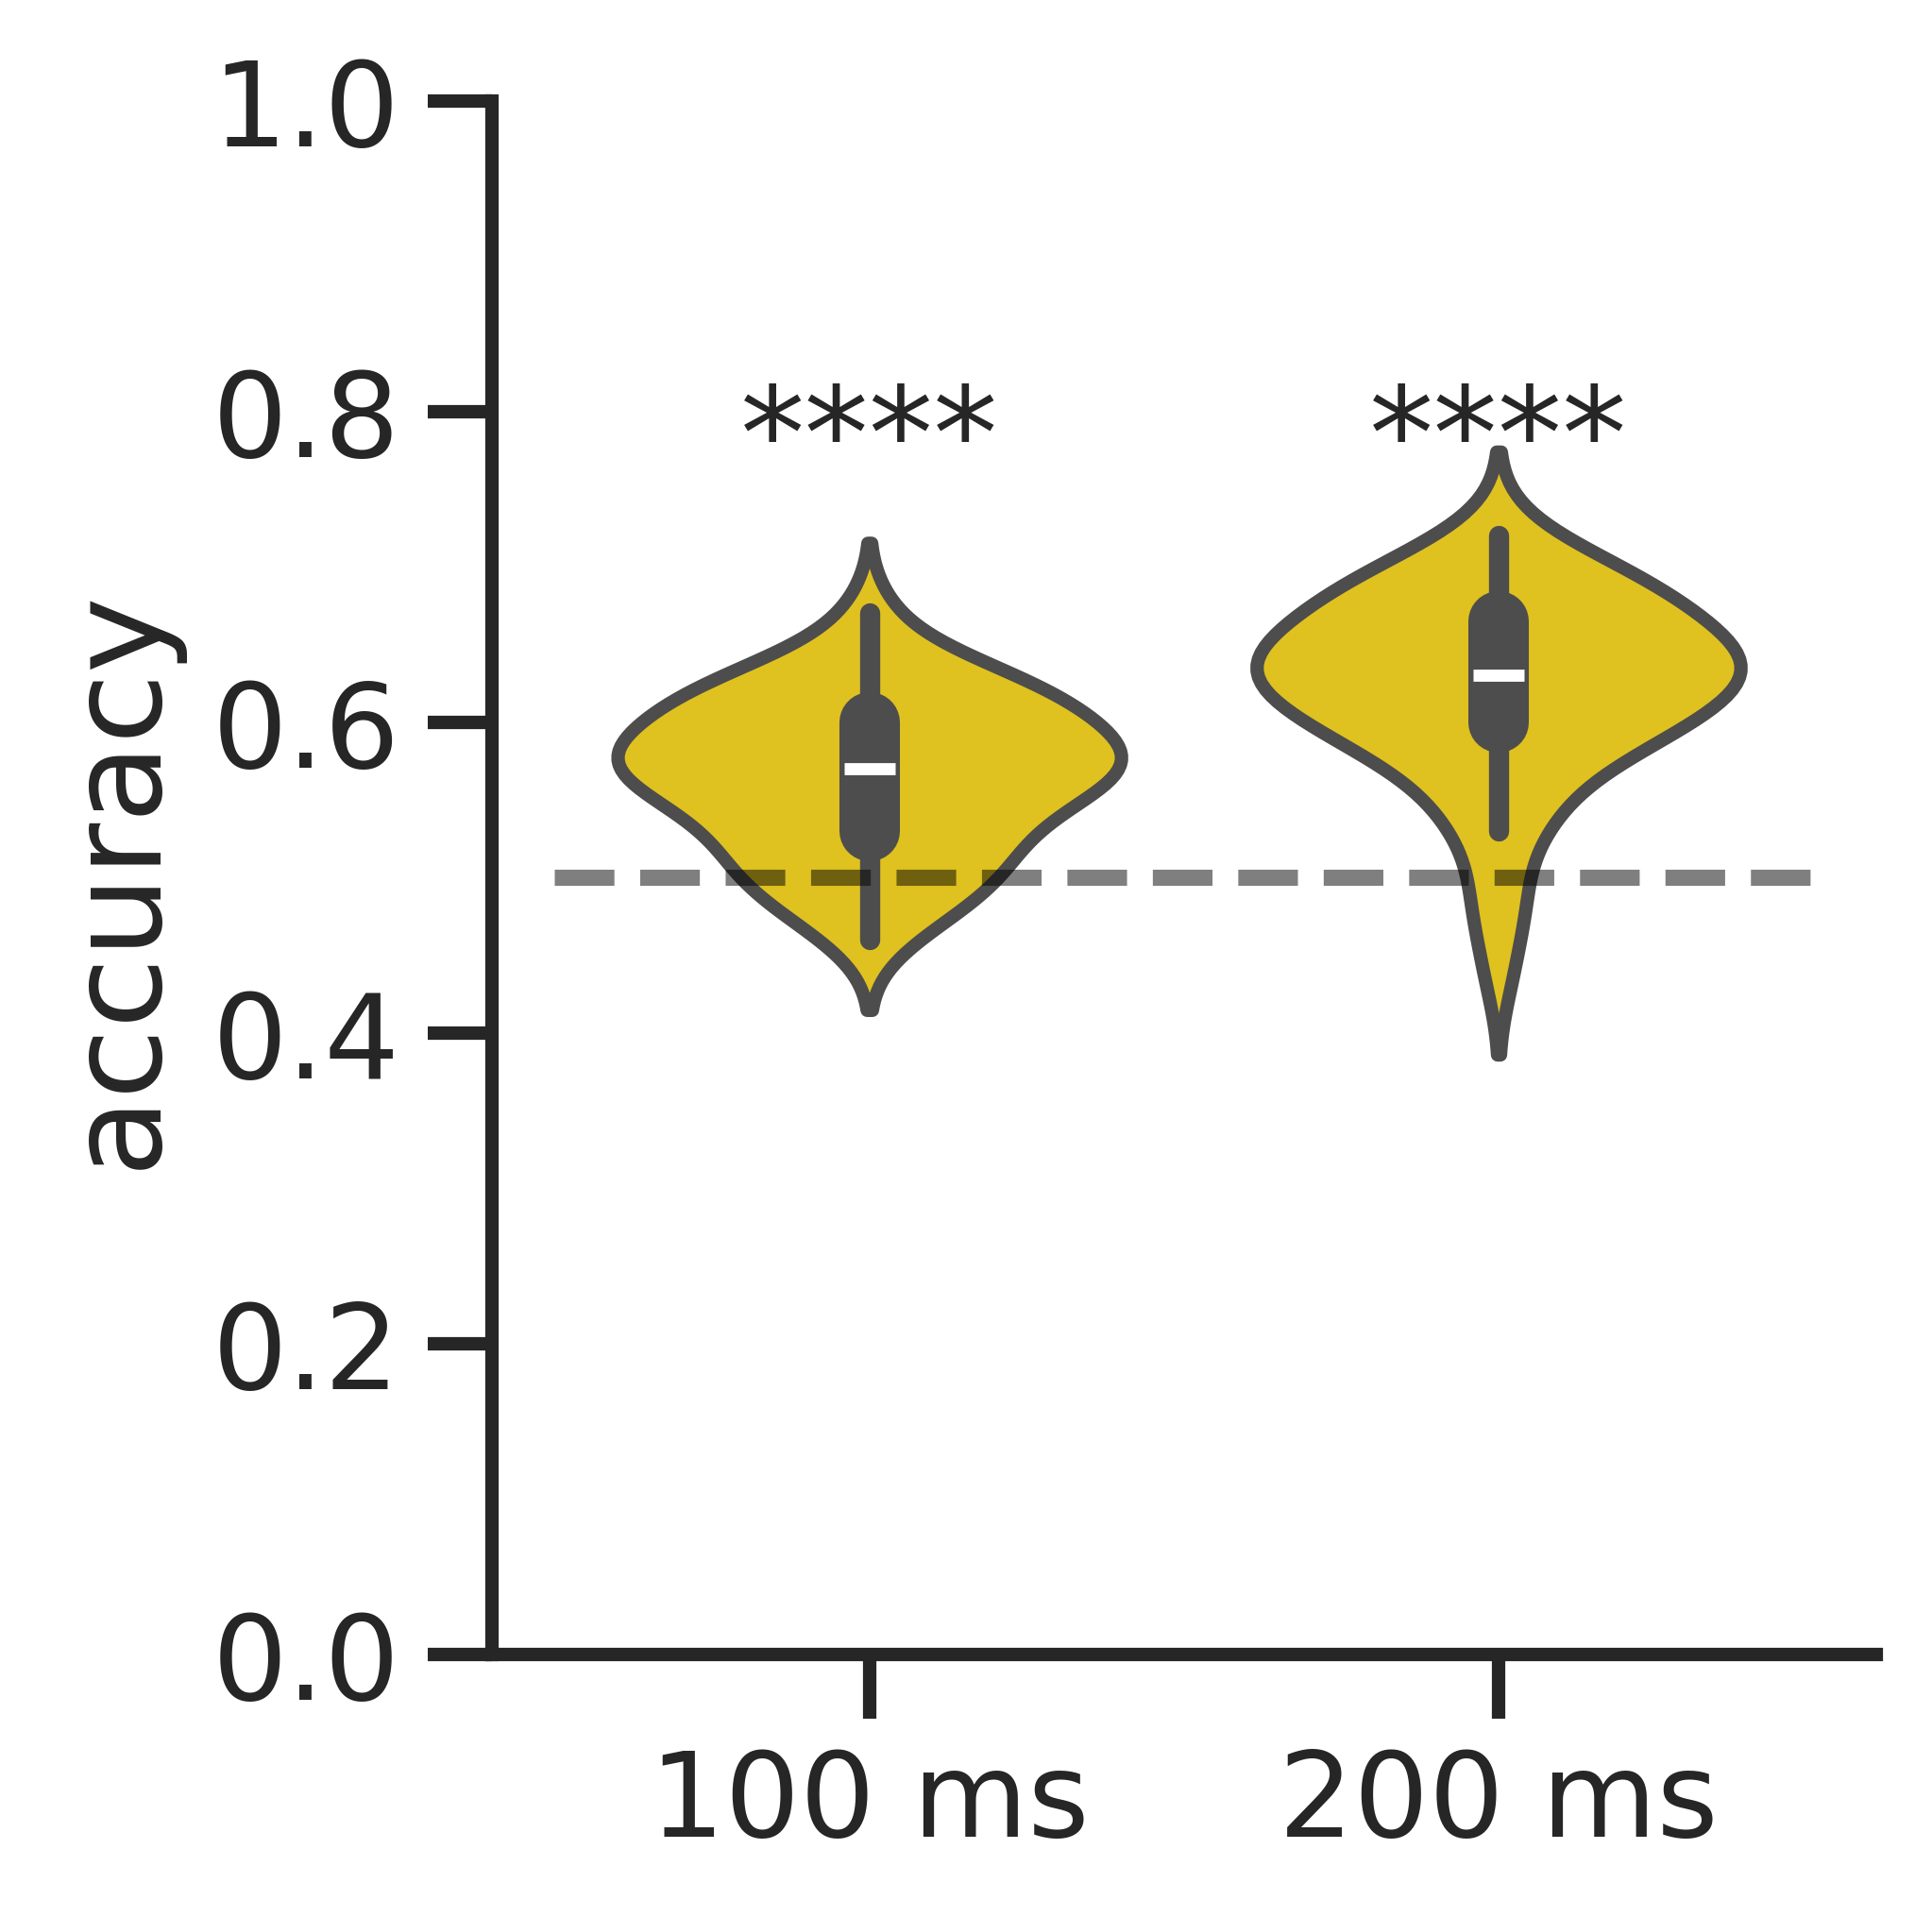

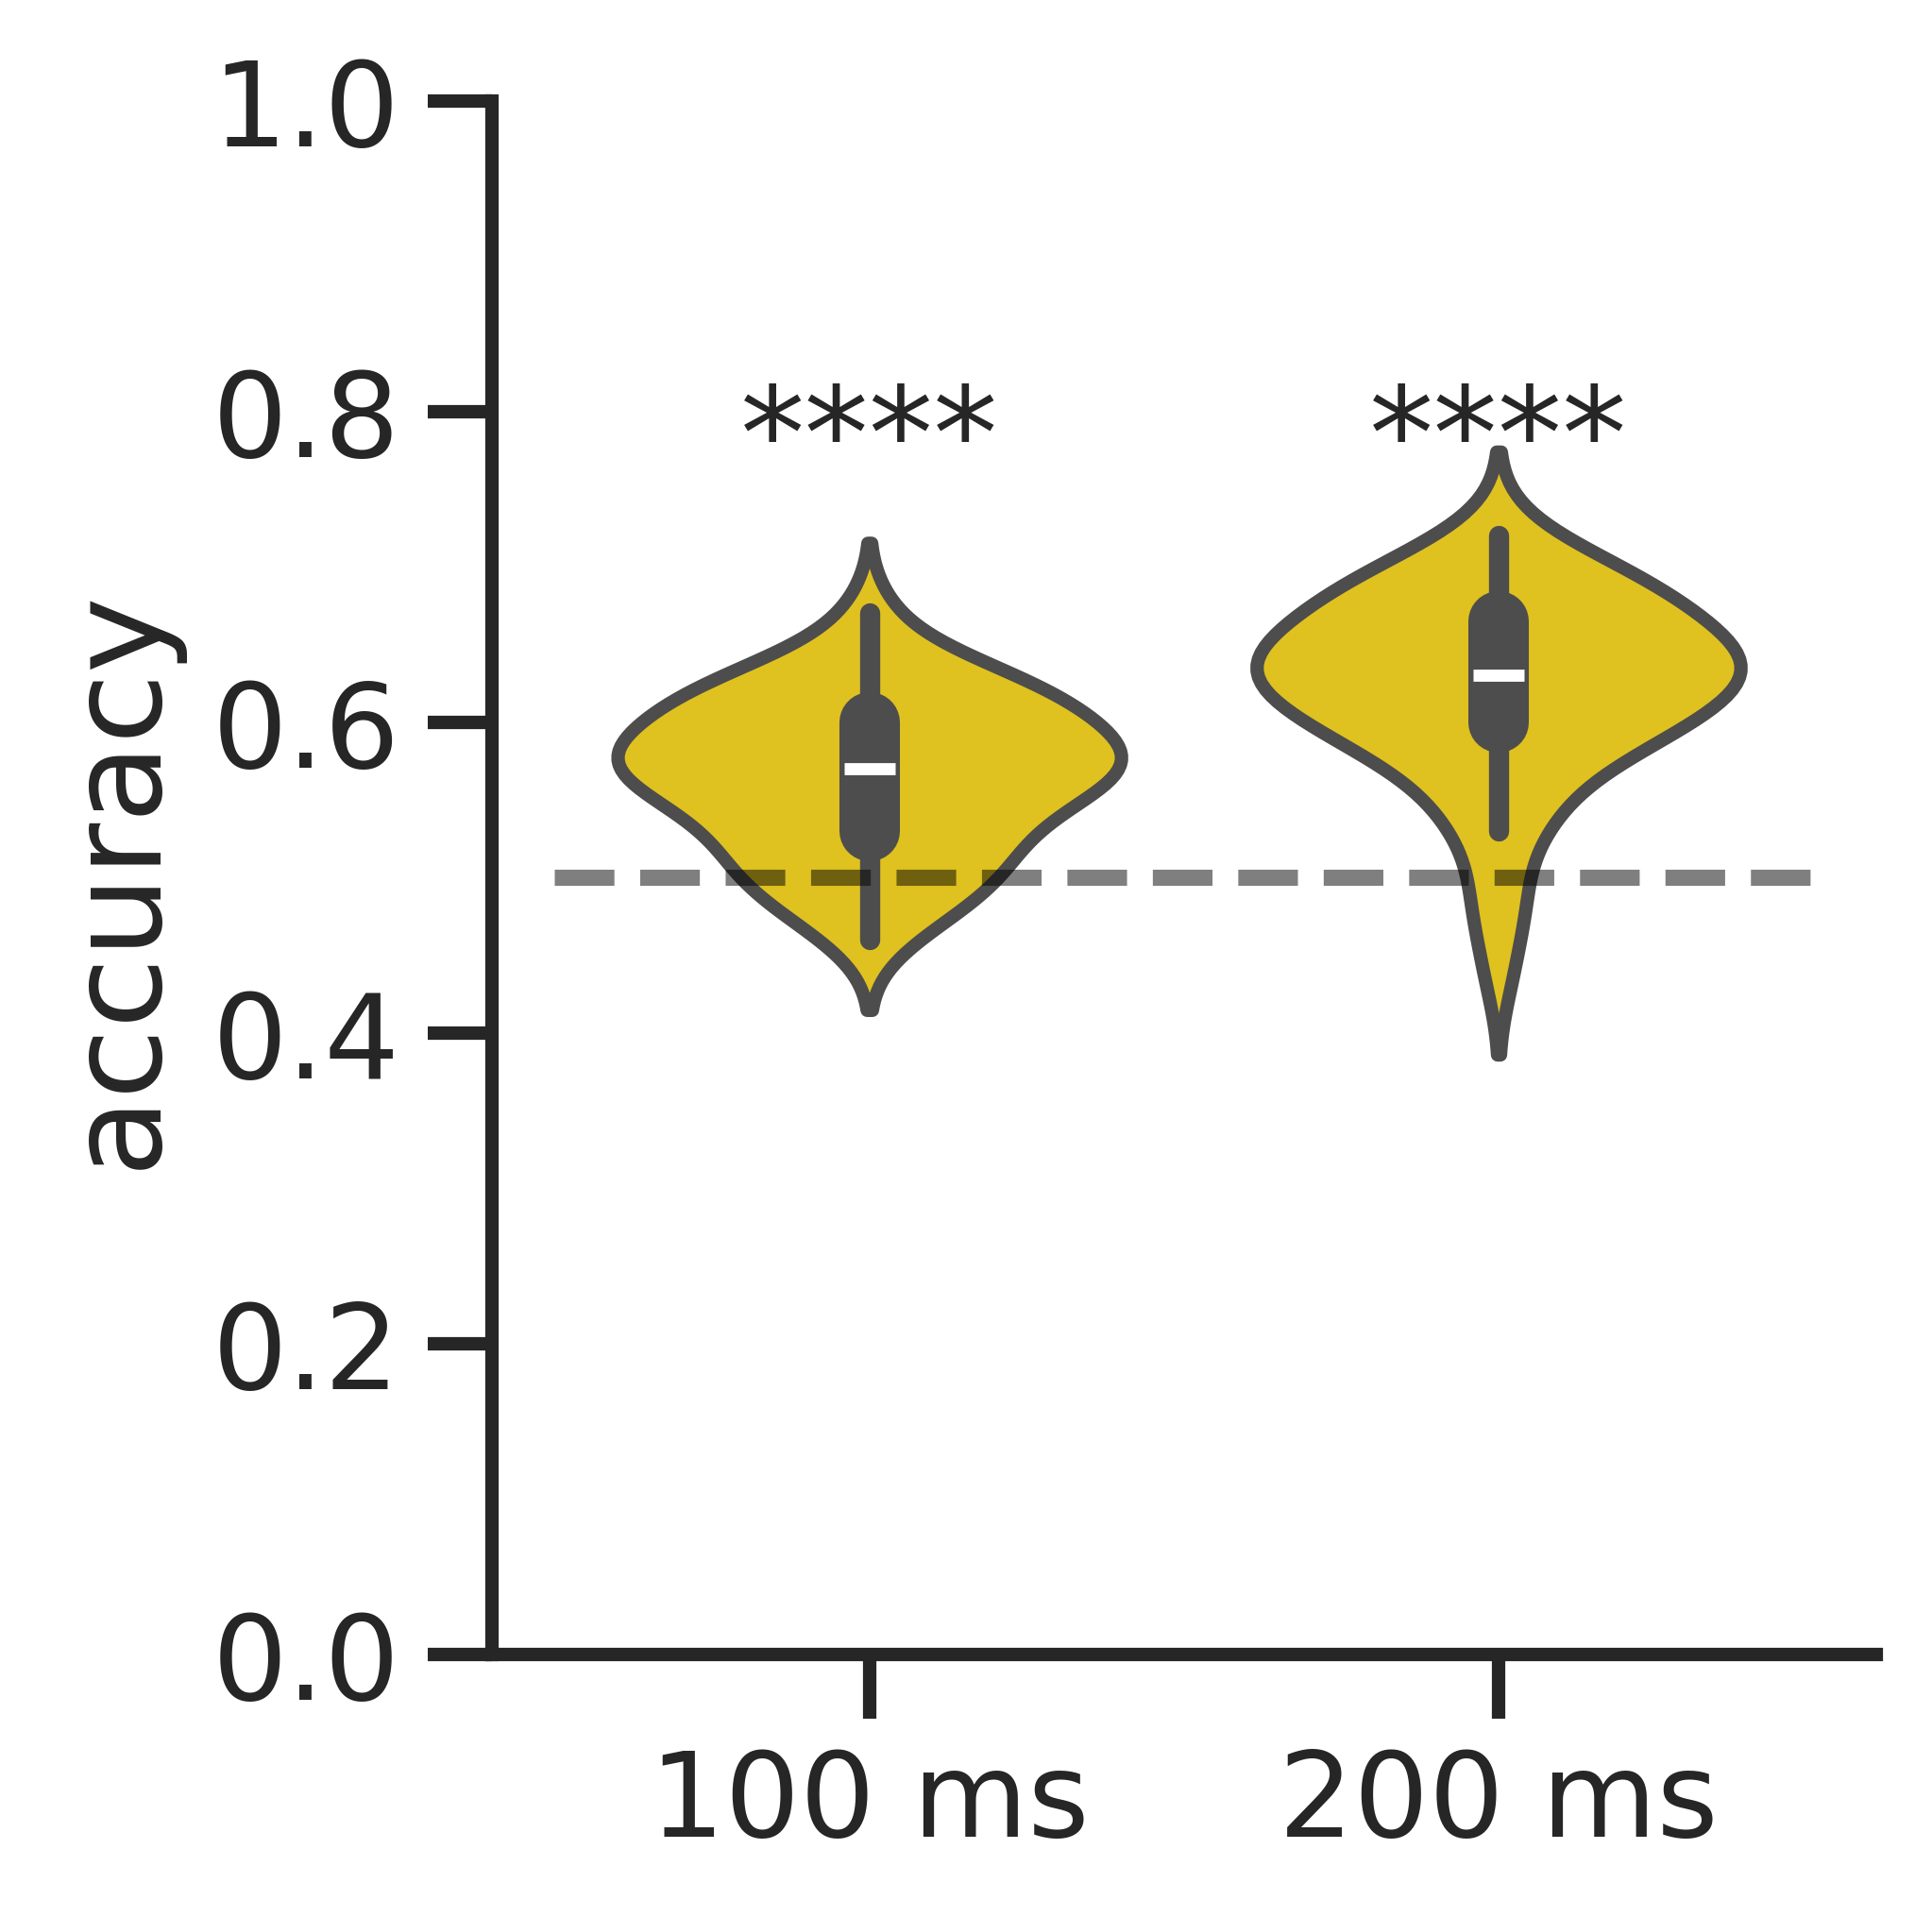

In [8]:
def stars(p):
    # significance marks come from the one-sample t-tests above
    for threshold, mark in ((1e-4, "****"), (1e-3, "***"), (1e-2, "**"), (5e-2, "*")):
        if p < threshold:
            return mark
    return "n.s."


plt.close("all")

# The axes box is fixed in inches with add_axes: plt.subplots sizes margins as fractions of the figure, so the
# box would rescale with it. The box comes from TARGET_AXIS_MM and AXES_W_MM, the text size from PANEL_SCALE.
AXES_W_MM = 2 * 733 / 600 * 25.4   # two violins, each 733 px wide at 600 dpi
MARGIN_MM = dict(left=16.0, right=3.0, bottom=10.0, top=3.0)  # generous; "tight" crops the surplus

fig_w = (MARGIN_MM["left"] + AXES_W_MM + MARGIN_MM["right"]) / 25.4
fig_h = (MARGIN_MM["bottom"] + TARGET_AXIS_MM + MARGIN_MM["top"]) / 25.4
fig = plt.figure(figsize=(fig_w, fig_h))
ax = fig.add_axes([
    MARGIN_MM["left"] / 25.4 / fig_w,
    MARGIN_MM["bottom"] / 25.4 / fig_h,
    AXES_W_MM / 25.4 / fig_w,
    TARGET_AXIS_MM / 25.4 / fig_h,
])

sns.violinplot(
    data=accuracy,
    x="time_point",
    y="accuracy",
    order=TIME_ORDER,
    ax=ax,
    fill=True,
    color="gold",
)
ax.set_ylabel("accuracy")
ax.set_xlabel("")
ax.set(ylim=(0, 1))
# fixed ticks: at this font size matplotlib would otherwise thin them to 0.0/0.5/1.0
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.hlines(0.5, *ax.get_xlim(), linestyles="dashed", colors="black", alpha=0.5)

for x, label in enumerate(TIME_ORDER):
    ax.text(x, 0.78, stars(summary.loc[label, "p"]), ha="center", va="center")

sns.despine(ax=ax)

fig.canvas.draw()
bb = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
print(f"axes box {bb.width * 25.4:.2f} x {bb.height * 25.4:.2f} mm "
      f"(target {AXES_W_MM:.2f} x {TARGET_AXIS_MM:.2f} mm)")

OUT_PNG = Path("../../artifacts/figures/revision/fig_5c_panel.png")
OUT_PNG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUT_PNG, bbox_inches="tight")
fig